# 12 · Análisis exploratorio: cuánto vale la historia y entrenar con meses recientes

**Etapa 15 del plan.** Del `08` al `11` se buscaron columnas nuevas y la mejora quedó cerca de 2 %. Este notebook cambia de pregunta.

**Hipótesis reformulada:** la historia de los clientes hace ganar más dinero, pero casi todo su valor está en los últimos 2 meses. Mirar más atrás suma poco, cerca de 2 %.

**Preguntas:**
1. ¿Cuánto vale la historia? `ACS` no tiene lags ni deltas.
2. ¿Entrenar con los meses más recientes gana más? Las configuraciones `_R` entrenan hasta dos meses antes del mes evaluado.
3. ¿La historia sigue sumando cuando el modelo ya tiene esos meses?
4. ¿Qué estrategia gana más dinero?

**Todo lo de este notebook es exploratorio.** 201909 y 201910 ya se miraron, así que nada de acá demuestra la hipótesis ni cambia el resultado de la regla pre-registrada.

**No escribe en `exp/03/` a `exp/11/` ni en los `resultados/03_*` a `11_*`:** solo los lee. **No usa la clase de 201911 ni de 201912.**

Ficha: `fichas/etapa_15_valor_historia_y_ventana.md` (en el laboratorio).

## 1. Parámetros

**Retomar:** si la corrida se corta, se vuelve a correr entera. Las semillas ya hechas no se repiten.

In [1]:
from pathlib import Path
import gc
import hashlib
import json
import resource
import sys
import time
import warnings

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter
from scipy import stats
from sklearn.metrics import roc_auc_score

# --- Parámetros -------------------------------------------------------------
BASE_PARQUET = Path('../data/base_2019.parquet')
RESULTADOS = Path('../resultados')
EXP_03 = Path('../exp/03')                          # solo se lee
EXP_06 = Path('../exp/06')                          # solo se lee
EXP_08 = Path('../exp/08')                          # solo se lee
EXP_09 = Path('../exp/09')                          # solo se lee
EXP_10 = Path('../exp/10')                          # solo se lee
EXP_11 = Path('../exp/11')                          # solo se lee
EXP = Path('../exp/12')
FIGURAS = RESULTADOS / 'figuras'

CONTROL = 'AC'
BASE_CURADA = 'ACH'
NUEVAS = {'ACH': {'lags': [], 'tendencia': None, 'curada': True}}   # la tabla de la que parten todas
SIN_LAGS = 'ACS'                                    # solo las variables del mes
COLUMNAS_PT = ['pt_1', 'pt_2', 'pt_3']
TRES = ['ACPH', 'ACPH_B', 'ACPH_C']
PARTICION = {'ACPH': 'A', 'ACPH_B': 'B', 'ACPH_C': 'C'}
RECIENTES = {'AC_R': 'AC', 'ACH_R': 'ACH', 'ACPH_R': 'ACPH', 'ACPH_R_B': 'ACPH_B', 'ACPH_R_C': 'ACPH_C'}  # con su versión de ventana actual
TRES_R = ['ACPH_R', 'ACPH_R_B', 'ACPH_R_C']
VENTANAS = {201909: [201903, 201904, 201905, 201906, 201907],     # mes evaluado: meses de entrenamiento
            201910: [201903, 201904, 201905, 201906, 201907, 201908]}
MES_EXTRA = 201907
CONTRASTES = {'ACS': ['AC'],
              'AC': ['ACH'] + TRES + ['AC_R', 'ACH_R'] + TRES_R,
              'AC_R': ['ACH_R'] + TRES_R,
              'ACH': ['ACH_R'], 'ACPH': ['ACPH_R'], 'ACPH_B': ['ACPH_R_B'], 'ACPH_C': ['ACPH_R_C']}

MESES_TRAIN = [201903, 201904, 201905, 201906]
MES_VALID = 201908
MESES_TEST = [201909, 201910]
MESES_EVAL = [MES_VALID] + MESES_TEST
ROTOS_EXTRA = [('ctarjeta_master_descuentos', 201910), ('mtarjeta_master_descuentos', 201910)]

BLOQUE = 20_000                                     # filas por bloque al armar las tablas
N_CURADAS = 30
MINIMO_PREVIOS = 2

SEMILLA_PRIMIGENIA = 979201
N_SEMILLAS = 10
N_BOOTSTRAP = 2_000
NIVEL_IC = 0.95
BANDA = (3_000, 6_000)                              # ambos incluidos
EPSILON = 1e-12
POSITIVOS = ['BAJA+1', 'BAJA+2']
N_HILOS = 8

GANANCIA_ACIERTO = 1_072_500
COSTO_ESTIMULO = 27_500
VENTANA_SUAVIZADO = 501
LARGO_CURVA = 25_000
# -----------------------------------------------------------------------------

PRED = EXP / 'pred'
VARIABLES_CSV = RESULTADOS / '08_variables.csv'     # solo se lee
for d in (PRED, FIGURAS):
    d.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings('ignore', message='.*ChainedAssignmentError.*')  # falso positivo pandas 2.2 + Py 3.14

ESPERADO_FILAS_POR_MES = {
    201901: 123_916, 201902: 125_020, 201903: 125_622, 201904: 126_116, 201905: 126_763,
    201906: 128_370, 201907: 129_853, 201908: 131_775, 201909: 133_419, 201910: 135_633,
}
ESPERADO_EVAL = {201908: (131_775, 543), 201909: (133_419, 615), 201910: (135_633, 632)}   # filas, BAJA+2
ESPERADO_N_VARIABLES = {'AC': 760, 'ACH': 880}
N_MES = 152
ESPERADO_ROTOS = 23
VARIABLE_COBERTURA = 'cproductos'


def primos_6_digitos():
    criba = np.ones(1_000_000, dtype=bool)
    criba[:2] = False
    for i in range(2, 1_001):
        if criba[i]:
            criba[i * i::i] = False
    return np.flatnonzero(criba[100_000:]) + 100_000


TODAS = np.random.default_rng(SEMILLA_PRIMIGENIA).choice(primos_6_digitos(), size=20, replace=False).tolist()[:10]
assert TODAS == [294103, 342929, 161093, 677561, 431077, 330679, 511579, 312773, 118147, 567529]
SEMILLAS = TODAS[:N_SEMILLAS]
assert N_SEMILLAS >= 2


def huella_archivos():
    """Control 10: huella de las salidas anteriores, para comprobar que no cambian."""
    return {p.name: hashlib.blake2b(p.read_bytes(), digest_size=16).hexdigest()
            for p in sorted([*RESULTADOS.glob('0[3456789]_*'), *RESULTADOS.glob('1[01]_*')])}


def memoria_gb():
    r = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    return round(r / (1e9 if sys.platform == 'darwin' else 1e6), 1)


HUELLA_INICIAL = huella_archivos()
T_INICIO = time.time()
print('Salidas anteriores registradas:', len(HUELLA_INICIAL))

Salidas anteriores registradas: 29


## 2. Dataset y funciones de evaluación

Las mismas funciones del `11`. La clase de 201909 y 201910 solo se usa en la evaluación.

**Control 1:** filas y `BAJA+2` de cada mes.

In [2]:
def curva(prob, es_b2):
    orden = np.argsort(-prob, kind='stable')
    return np.cumsum(np.where(es_b2[orden], GANANCIA_ACIERTO, -COSTO_ESTIMULO))[:LARGO_CURVA].astype(np.float64)


def elegir_n(curva_media):
    suave = pd.Series(curva_media).rolling(VENTANA_SUAVIZADO, center=True, min_periods=VENTANA_SUAVIZADO).mean().to_numpy()
    return int(np.nanargmax(suave)) + 1


def banda(cv):
    return cv[..., BANDA[0] - 1:BANDA[1]].mean(axis=-1)


def wilcoxon_exacto(d):
    d = np.round(np.asarray(d, dtype=np.float64), 6)
    d = d[d != 0]
    n = len(d)
    if n == 0:
        return 1.0
    rangos = stats.rankdata(np.abs(d))
    w = float((np.sign(d) * rangos).sum())
    signos = 1 - 2 * ((np.arange(2 ** n)[:, None] >> np.arange(n)) & 1)
    return float(np.mean(np.abs(signos @ rangos) >= abs(w) - 1e-9))


def ic(x):
    x = np.asarray(x, dtype=np.float64)
    media = x.mean()
    medio = stats.t.ppf((1 + NIVEL_IC) / 2, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))
    return media, media - medio, media + medio


assert abs(wilcoxon_exacto(np.arange(1, 11)) - 2 / 1024) < 1e-12
assert abs(wilcoxon_exacto([1, 1, 1, 1, 1, 1, 1, 1, 1, -1]) - 22 / 1024) < 1e-12

HIPER = json.loads((RESULTADOS / '03_hiperparametros.json').read_text())
semillas_06 = pd.read_csv(RESULTADOS / '06_semillas.csv')
HUELLA_AC = json.loads((EXP_06 / 'huellas.json').read_text())[CONTROL]
cobertura = pd.read_csv(RESULTADOS / '01_cobertura_historia.csv', index_col='foto_mes')
claves_npz = np.load(EXP_03 / 'claves_eval.npz')
CLIENTE_EVAL, MES = claves_npz['numero_de_cliente'], claves_npz['foto_mes']

t0 = time.time()
con = duckdb.connect()
base = con.execute(f"""
    select * from read_parquet('{BASE_PARQUET.as_posix()}')
    where foto_mes <= {max(MESES_TEST)}
    order by foto_mes, numero_de_cliente
""").df()
con.close()
assert base['foto_mes'].value_counts().sort_index().to_dict() == ESPERADO_FILAS_POR_MES

CLAVES = ['numero_de_cliente', 'foto_mes', 'clase_ternaria']
VARIABLES = [c for c in base.columns if c not in CLAVES]
BANDERAS = ['active_quarter', 'cliente_vip', 'internet', 'cdescubierto_preacordado',
            'tcallcenter', 'thomebanking', 'tmobile_app', 'ccajas_transacciones']
ESTADOS = ['tcuentas', 'Visa_status', 'Master_status', 'Visa_delinquency', 'Master_delinquency']
FECHAS = [f'{t}_{c}' for t in ('Visa', 'Master') for c in ('Fvencimiento', 'Finiciomora', 'fultimo_cierre', 'fechaalta')]
EDADES = ['cliente_edad', 'cliente_antiguedad']
MONTOS = [v for v in VARIABLES if v not in BANDERAS + ESTADOS + FECHAS + EDADES]
assert len(VARIABLES) == 152 and len(MONTOS) == 129

rotos = pd.read_csv(RESULTADOS / '01_meses_rotos.csv')[['variable', 'foto_mes']]
assert len(rotos) == ESPERADO_ROTOS
rotos = pd.concat([rotos, pd.DataFrame(ROTOS_EXTRA, columns=['variable', 'foto_mes'])], ignore_index=True)
for v, mes in rotos.itertuples(index=False):
    base.loc[base['foto_mes'] == mes, v] = np.nan

FOTO_MES = base['foto_mes'].to_numpy()
PERIODO = (FOTO_MES // 100 * 12 + FOTO_MES % 100).astype(np.int64)
CLAVE = base['numero_de_cliente'].to_numpy(np.int64) * 100_000 + PERIODO
INDICE = pd.Index(CLAVE)
assert INDICE.is_unique
X_MES = np.asfortranarray(base[VARIABLES].to_numpy(np.float32))
CLASE = base['clase_ternaria'].to_numpy()
clase_eval = base.loc[base['foto_mes'].isin(MESES_EVAL), ['numero_de_cliente', 'foto_mes', 'clase_ternaria']]
del base
gc.collect()

eval_ = pd.DataFrame({'numero_de_cliente': CLIENTE_EVAL, 'foto_mes': MES}).merge(
    clase_eval, on=['numero_de_cliente', 'foto_mes'], how='left', validate='one_to_one')
assert eval_['clase_ternaria'].notna().all()
ES_B2 = (eval_['clase_ternaria'] == 'BAJA+2').to_numpy()
es_mes = {m: MES == m for m in MESES_EVAL}
for mes, (filas, b2) in ESPERADO_EVAL.items():            # control 1
    assert (es_mes[mes].sum(), ES_B2[es_mes[mes]].sum()) == (filas, b2), mes
print(f'Dataset cargado en {time.time() - t0:.0f} s · {len(rotos)} casos de meses rotos a NA')

Dataset cargado en 1 s · 25 casos de meses rotos a NA


## 3. Tablas

La misma construcción del `11`.

In [3]:
SIN_HISTORIA = {'lags': [], 'tendencia': None, 'curada': False}
CURADAS = []


def receta(config):
    return SIN_HISTORIA if config == CONTROL else NUEVAS[config]


def especificacion(config):
    ex = receta(config)
    e = [('original', v, 0) for v in VARIABLES]
    e += [(op, v, k) for k in (1, 2) for op in ('lag', 'delta') for v in VARIABLES]
    for k in ex['lags']:
        e += [(op, v, k) for op in ('lag', 'delta') for v in MONTOS + BANDERAS]
        e += [(op, v, k) for op in ('lag', 'cambio') for v in ESTADOS]
    if ex['tendencia']:
        h = ex['tendencia']
        e += [(op, v, h) for op in ('pend', 'prom', 'min', 'max') for v in MONTOS]
        e += [('perm', v, h) for v in BANDERAS]
    if ex['curada']:
        assert len(CURADAS) == N_CURADAS
        e += [(op, v, k) for op, k in (('ratio', 3), ('z', 4), ('relmax', 4), ('mes_ratio', 3)) for v in CURADAS]
    return e


def nombre(op, v, k):
    return v if op == 'original' else f'{v}_{op}{k}'


def construir(config, meses=None):
    ex = receta(config)
    h = ex['tendencia']
    h_max = max([2] + ex['lags'] + [h or 0] + ([4] if ex['curada'] else []))
    filas = np.flatnonzero(np.isin(FOTO_MES, meses or MESES_TRAIN + MESES_EVAL))
    mes_fila = FOTO_MES[filas]
    n_train = int(np.isin(mes_fila, MESES_TRAIN).sum())
    assert meses or (np.isin(mes_fila[:n_train], MESES_TRAIN).all() and np.isin(mes_fila[n_train:], MESES_EVAL).all())
    pos = {k: INDICE.get_indexer(CLAVE[filas] - k) for k in range(h_max + 1)}

    espec = especificacion(config)
    ubic = {e: i for i, e in enumerate(espec)}
    F = np.empty((len(filas), len(espec)), dtype=np.float32)
    t = -np.arange((h or 0) + 1, dtype=np.float64)[:, None]
    # Por bloques de filas: escribir columna por columna recorre toda la tabla en cada pasada,
    # y con una tabla de más de ~4,5 GB eso tardó decenas de minutos.
    with np.errstate(invalid='ignore', divide='ignore'):
        for inicio in range(0, len(filas), BLOQUE):
            fb = slice(inicio, inicio + BLOQUE)
            for j, v in enumerate(VARIABLES):
                F[fb, ubic[('original', v, 0)]] = X_MES[filas[fb], j]
                hk = {}
                for k in range(h_max + 1):
                    col = X_MES[pos[k][fb], j]
                    col[pos[k][fb] < 0] = np.nan
                    hk[k] = col
                for k in range(1, h_max + 1):
                    if ('lag', v, k) in ubic:
                        F[fb, ubic[('lag', v, k)]] = hk[k]
                    if ('delta', v, k) in ubic:
                        F[fb, ubic[('delta', v, k)]] = hk[0] - hk[k]
                    if ('cambio', v, k) in ubic:
                        a, b = hk[0], hk[k]
                        F[fb, ubic[('cambio', v, k)]] = np.where(np.isnan(a) | np.isnan(b), np.nan, (a != b).astype(np.float32))
                if h and (('prom', v, h) in ubic or ('perm', v, h) in ubic):
                    S = np.stack([hk[k] for k in range(h + 1)]).astype(np.float64)
                    valido = ~np.isnan(S)
                    cuantos = valido.sum(axis=0)
                    S0 = np.where(valido, S, 0.0)
                    if ('perm', v, h) in ubic:
                        F[fb, ubic[('perm', v, h)]] = np.where(cuantos > 0, S0.sum(axis=0), np.nan)
                    else:
                        prom = S0.sum(axis=0) / cuantos
                        dt = np.where(valido, t - (valido * t).sum(axis=0) / cuantos, 0.0)
                        pend = (dt * (S0 - prom)).sum(axis=0) / (dt ** 2).sum(axis=0)
                        pend[cuantos < 2] = np.nan
                        F[fb, ubic[('pend', v, h)]] = pend
                        F[fb, ubic[('prom', v, h)]] = prom
                        F[fb, ubic[('min', v, h)]] = np.where(cuantos > 0, np.where(valido, S, np.inf).min(axis=0), np.nan)
                        F[fb, ubic[('max', v, h)]] = np.where(cuantos > 0, np.where(valido, S, -np.inf).max(axis=0), np.nan)
                if ('ratio', v, 3) in ubic:
                    a, b, c = (hk[k].astype(np.float64) for k in range(3))
                    media3 = (a + b + c) / 3                  # NA si falta alguna foto
                    ratio = np.where(np.abs(media3) > EPSILON, a / media3, np.nan)
                    F[fb, ubic[('ratio', v, 3)]] = ratio
                    x = a
                    P = np.stack([hk[k] for k in range(1, 5)]).astype(np.float64)
                    valido = ~np.isnan(P)
                    cuantos = valido.sum(axis=0)
                    alcanza = (cuantos >= MINIMO_PREVIOS) & ~np.isnan(x)
                    media = np.where(valido, P, 0.0).sum(axis=0) / cuantos
                    desvio = np.sqrt(np.where(valido, (P - media) ** 2, 0.0).sum(axis=0) / cuantos)
                    maximo = np.where(valido, P, -np.inf).max(axis=0)
                    F[fb, ubic[('z', v, 4)]] = np.where(alcanza & (desvio > EPSILON), (x - media) / desvio, np.nan)
                    F[fb, ubic[('relmax', v, 4)]] = np.where(alcanza & (maximo > EPSILON), x / maximo, np.nan)
    for v in (CURADAS if ex['curada'] else []):           # el percentil necesita el mes entero
        F[:, ubic[('mes_ratio', v, 3)]] = pd.Series(F[:, ubic[('ratio', v, 3)]]).groupby(mes_fila).rank(pct=True).to_numpy(np.float32)
    return {'F': F, 'columnas': [nombre(*e) for e in espec], 'espec': espec, 'filas': filas, 'mes_fila': mes_fila,
            'n_train': n_train, 'lags': sorted({k for op, _, k in espec if op == 'lag'}), 'h': h}


def huella_control(T):
    """La huella del 06, columna por columna. Solo se calcula sobre la tabla de AC: en una tabla grande es muy lenta."""
    hsh = hashlib.blake2b(digest_size=16)
    hsh.update(T['filas'].tobytes())
    for j in range(ESPERADO_N_VARIABLES[CONTROL]):
        hsh.update(T['F'][:, j].tobytes())
    return hsh.hexdigest()


def huella_filas(T):
    """Las primeras 760 columnas, leídas por bloques de filas."""
    hsh = hashlib.blake2b(digest_size=16)
    hsh.update(T['filas'].tobytes())
    for inicio in range(0, len(T['filas']), BLOQUE):
        hsh.update(np.ascontiguousarray(T['F'][inicio:inicio + BLOQUE, :ESPERADO_N_VARIABLES[CONTROL]]).tobytes())
    return hsh.hexdigest()


def controlar(T, config):
    F, col, mes_fila = T['F'], {c: i for i, c in enumerate(T['columnas'])}, T['mes_fila']
    ex = receta(config)
    assert F.shape[1] == ESPERADO_N_VARIABLES[config], F.shape            # control 2
    if config == CONTROL:                                                 # control 3
        assert huella_control(T) == HUELLA_AC, 'Las columnas de A no son las de AC'
    else:
        assert huella_filas(T) == HUELLA_FILAS, 'Las columnas de A no son las de AC'
    evalua = slice(T['n_train'], None)                                    # control 4
    assert (CLAVE[T['filas'][evalua]] // 100_000 == CLIENTE_EVAL).all() and (mes_fila[evalua] == MES).all()

    for k in [k for k in T['lags'] if k >= 2]:                            # control 5: cobertura
        pct = pd.Series(~np.isnan(F[:, col[f'{VARIABLE_COBERTURA}_lag{k}']])).groupby(mes_fila).mean().mul(100)
        for mes, valor in pct.items():
            assert abs(valor - cobertura.loc[mes, f'h{k}']) <= 0.051, (k, mes, valor)

    rng = np.random.default_rng(SEMILLA_PRIMIGENIA)                       # control 6: fórmulas a mano
    muestra = rng.choice(len(T['filas']), size=4_000, replace=False)
    claves_muestra = CLAVE[T['filas'][muestra]]

    def historia(v, largo):
        valores = pd.Series(X_MES[:, VARIABLES.index(v)].astype(np.float64), index=INDICE)
        return np.stack([valores.reindex(claves_muestra - k).to_numpy() for k in range(largo)])

    for k in ex['lags']:
        for v in ('ctrx_quarter', 'cpayroll_trx', 'Visa_status'):
            np.testing.assert_array_equal(F[muestra, col[f'{v}_lag{k}']], historia(v, k + 1)[k].astype(np.float32))
    if T['h']:
        h, v = T['h'], 'ctrx_quarter'
        y = historia(v, h + 1)
        for j in rng.choice(np.flatnonzero(~np.isnan(y).any(axis=0)), size=5, replace=False):
            i = muestra[j]
            np.testing.assert_allclose(
                [F[i, col[f'{v}_pend{h}']], F[i, col[f'{v}_prom{h}']], F[i, col[f'{v}_min{h}']], F[i, col[f'{v}_max{h}']]],
                [np.polyfit(-np.arange(h + 1), y[:, j], 1)[0], y[:, j].mean(), y[:, j].min(), y[:, j].max()], rtol=1e-4, atol=1e-4)
    if ex['curada']:
        for v in CURADAS[:3]:
            y = historia(v, 5)
            x, previos = y[0], y[1:]
            media3 = y[:3].mean(axis=0)
            usa = ~np.isnan(media3) & (np.abs(media3) > EPSILON)
            np.testing.assert_allclose(F[muestra[usa], col[f'{v}_ratio3']], x[usa] / media3[usa], rtol=1e-4)
            assert np.isnan(F[muestra[~usa], col[f'{v}_ratio3']]).all()
            with warnings.catch_warnings():
                warnings.simplefilter('ignore', RuntimeWarning)
                media, desvio, maximo = np.nanmean(previos, axis=0), np.nanstd(previos, axis=0), np.nanmax(previos, axis=0)
            alcanza = ((~np.isnan(previos)).sum(axis=0) >= MINIMO_PREVIOS) & ~np.isnan(x)
            usa = alcanza & (desvio > EPSILON)
            np.testing.assert_allclose(F[muestra[usa], col[f'{v}_z4']], (x[usa] - media[usa]) / desvio[usa], rtol=1e-3, atol=1e-4)
            assert np.isnan(F[muestra[~usa], col[f'{v}_z4']]).all()
            usa = alcanza & (maximo > EPSILON)
            np.testing.assert_allclose(F[muestra[usa], col[f'{v}_relmax4']], x[usa] / maximo[usa], rtol=1e-4)
            assert np.isnan(F[muestra[~usa], col[f'{v}_relmax4']]).all()
            for mes in MESES_TRAIN[:1] + MESES_EVAL[:1]:                  # percentil dentro del mes
                en_mes = mes_fila == mes
                r, p = F[en_mes, col[f'{v}_ratio3']], F[en_mes, col[f'{v}_mes_ratio3']]
                assert (np.isnan(r) == np.isnan(p)).all()
                orden = np.argsort(r[~np.isnan(r)], kind='stable')
                assert (np.diff(p[~np.isnan(r)][orden]) >= 0).all() and p[~np.isnan(p)].max() <= 1

    periodo_fila = mes_fila // 100 * 12 + mes_fila % 100                  # control 7: meses rotos
    for v, mes in rotos.itertuples(index=False):
        p = (mes // 100) * 12 + mes % 100
        for k in [0] + T['lags']:
            columna = v if k == 0 else f'{v}_lag{k}'
            destino = periodo_fila == p + k
            if destino.any() and columna in col:
                assert np.isnan(F[destino, col[columna]]).all(), (v, mes, k)
        if ex['curada'] and v in CURADAS:
            for k in range(3):
                destino = periodo_fila == p + k
                if destino.any():
                    assert np.isnan(F[destino, col[f'{v}_ratio3']]).all(), (v, mes, k)
            destino = periodo_fila == p
            if destino.any():
                assert np.isnan(F[destino, col[f'{v}_z4']]).all() and np.isnan(F[destino, col[f'{v}_relmax4']]).all(), (v, mes)

## 4. Variables curadas y controles de `AC`

In [4]:
FIJOS = {'objective': 'binary', 'metric': 'auc', 'boosting': 'gbdt', 'max_bin': 31, 'bagging_freq': 1,
         'lambda_l1': 0.0, 'lambda_l2': 0.0, 'min_gain_to_split': 0.0, 'feature_pre_filter': False,
         'num_threads': N_HILOS, 'deterministic': True, 'force_col_wise': True, 'verbose': -1}
MEJORES = {**FIJOS, **HIPER['params']}
ARBOLES = HIPER['arboles']


def datos(T):
    n = T['n_train']
    assert np.isin(FOTO_MES[T['filas'][:n]], MESES_TRAIN).all()           # control 8
    y_train = np.isin(CLASE[T['filas'][:n]], POSITIVOS).astype(np.int8)
    return lgb.Dataset(T['F'][:n], label=y_train, feature_name=T['columnas'],
                       params={'max_bin': 31, 'feature_pre_filter': False}, free_raw_data=False)


CURADAS = pd.read_csv(VARIABLES_CSV)['variable'].tolist()
assert len(CURADAS) == N_CURADAS and set(CURADAS) <= set(MONTOS)

def ruta(config, semilla, mes=None):
    return PRED / config / f'{semilla}.npy' if mes is None else PRED / config / str(mes) / f'{semilla}.npy'


def pendientes(config, mes=None):
    return [s for s in SEMILLAS if not ruta(config, s, mes).exists()]


FALTA_ACS = pendientes(SIN_LAGS)
FALTA_R = {(c, m): pendientes(c, m) for c in RECIENTES for m in VENTANAS}
HAY_MODELOS = bool(FALTA_ACS) or any(FALTA_R.values())
if HAY_MODELOS:
    T = construir(CONTROL)
    controlar(T, CONTROL)
    HUELLA_FILAS = huella_filas(T)
print('Modelos pendientes:', len(FALTA_ACS) + sum(len(v) for v in FALTA_R.values()))

Modelos pendientes: 110


## 5. Modelos

**Ventana reciente:** para cada mes evaluado se entrena hasta dos meses antes, porque recién entonces se conoce la clase. Usa los puntajes ya calculados.

**Control 2:** `ACH`, reentrenada con este código y la primera semilla, da las predicciones del `08`.

**Control 5:** 201907 se arma junto con 201908, y esas filas tienen que coincidir con las de la tabla principal.

**Control 6:** cada modelo usa solo clase de hasta dos meses antes del mes evaluado.

**Control 7:** `ACS` usa solo las columnas del mes.

In [5]:
def posiciones(filas, hasta=3):
    return {k: INDICE.get_indexer(CLAVE[filas] - k) for k in range(hasta + 1)}


def columnas_puntaje(filas, percentil_base):
    pos = posiciones(filas)
    salida = []
    for k in (1, 2, 3):
        p = percentil_base[pos[k]].astype(np.float32)
        p[pos[k] < 0] = np.nan
        salida.append(p)
    return np.column_stack(salida)


def periodo(mes):
    return mes // 100 * 12 + mes % 100


def conjunto(F, filas, columnas):
    y = np.isin(CLASE[filas], POSITIVOS).astype(np.int8)
    # Se construye dentro de lgb.train, igual que en el 08: la semilla interviene en los bins.
    return lgb.Dataset(F, label=y, feature_name=columnas, params={'max_bin': 31, 'feature_pre_filter': False}, free_raw_data=False)


def tabla_extra(config, T):
    """201907 no está en la tabla principal. Se arma junto con 201908 para comprobar que da lo mismo."""
    J = construir(config, meses=[MES_EXTRA, MES_VALID])
    agosto = J['mes_fila'] == MES_VALID
    assert np.array_equal(J['F'][agosto], T['F'][T['mes_fila'] == MES_VALID], equal_nan=True), 'control 5'
    julio = ~agosto
    assert julio.sum() == ESPERADO_FILAS_POR_MES[MES_EXTRA]
    columna = {c: i for i, c in enumerate(J['columnas'])}
    for v, mes in rotos.itertuples(index=False):
        if mes == MES_EXTRA:
            assert np.isnan(J['F'][julio, columna[v]]).all(), v
    return {'F': J['F'][julio], 'filas': J['filas'][julio]}


def correr_ventanas(config, T, E, F=None, F_extra=None, columnas=None):
    F = T['F'] if F is None else F
    F_extra = E['F'] if F_extra is None else F_extra
    columnas = columnas or T['columnas']
    for mes, meses in VENTANAS.items():
        falta = pendientes(config, mes)
        if not falta:
            continue
        ruta(config, falta[0], mes).parent.mkdir(parents=True, exist_ok=True)
        usa = np.isin(T['mes_fila'], meses)
        filas = np.concatenate([T['filas'][usa], E['filas']])
        assert sorted(set(FOTO_MES[filas])) == meses, 'control 6'
        assert periodo(FOTO_MES[filas].max()) == periodo(mes) - 2, 'control 6'
        dtrain = conjunto(np.vstack([F[usa], F_extra]), filas, columnas)
        X_mes = F[T['mes_fila'] == mes]
        print(f'{config} · {mes}: {len(filas):,} filas, {len(columnas):,} variables · memoria máxima {memoria_gb()} GB')
        for semilla in falta:
            t0 = time.time()
            modelo = lgb.train({**MEJORES, 'seed': semilla}, dtrain, num_boost_round=ARBOLES)
            prob = modelo.predict(X_mes, num_threads=N_HILOS).astype(np.float32)
            np.save(ruta(config, semilla, mes), prob)     # al final: si existe, la semilla está completa
            segundos.setdefault(config, []).append(time.time() - t0)
            print(f'{config} · {mes} · semilla {semilla}: {time.time() - t0:.0f} s')
        del dtrain, X_mes, modelo, prob
        gc.collect()


segundos = {}
if HAY_MODELOS:
    if FALTA_ACS:                                         # sin historia
        assert T['columnas'][:N_MES] == VARIABLES, 'control 7'
        (PRED / SIN_LAGS).mkdir(exist_ok=True)
        dtrain = conjunto(np.ascontiguousarray(T['F'][:T['n_train'], :N_MES]), T['filas'][:T['n_train']], VARIABLES)
        X_eval = np.ascontiguousarray(T['F'][T['n_train']:, :N_MES])
        for semilla in FALTA_ACS:
            t0 = time.time()
            modelo = lgb.train({**MEJORES, 'seed': semilla}, dtrain, num_boost_round=ARBOLES)
            np.save(ruta(SIN_LAGS, semilla), modelo.predict(X_eval, num_threads=N_HILOS).astype(np.float32))
            segundos.setdefault(SIN_LAGS, []).append(time.time() - t0)
            print(f'{SIN_LAGS} · semilla {semilla}: {time.time() - t0:.0f} s')
        del dtrain, X_eval, modelo
        gc.collect()

    if any(FALTA_R[('AC_R', m)] for m in VENTANAS):
        correr_ventanas('AC_R', T, tabla_extra(CONTROL, T))
    del T
    gc.collect()

    T = construir(BASE_CURADA)
    controlar(T, BASE_CURADA)
    dtrain = conjunto(T['F'][:T['n_train']], T['filas'][:T['n_train']], T['columnas'])     # control 2
    modelo = lgb.train({**MEJORES, 'seed': SEMILLAS[0]}, dtrain, num_boost_round=ARBOLES)
    prob = modelo.predict(T['F'][T['n_train']:], num_threads=N_HILOS).astype(np.float32)
    assert np.array_equal(prob, np.load(EXP_08 / 'pred' / BASE_CURADA / f'{SEMILLAS[0]}.npy')), 'ACH no reproduce el 08'
    del dtrain, modelo, prob
    gc.collect()
    print('Control 2 OK')

    E = tabla_extra(BASE_CURADA, T)
    correr_ventanas('ACH_R', T, E)
    base = {'A': np.load(EXP_09 / 'puntajes.npy'), 'B': np.load(EXP_10 / 'puntajes_B.npy'), 'C': np.load(EXP_10 / 'puntajes_C.npy')}
    for config in TRES_R:
        if not any(FALTA_R[(config, m)] for m in VENTANAS):
            continue
        parte = base[PARTICION[RECIENTES[config]]]
        F = np.hstack([T['F'], columnas_puntaje(T['filas'], parte)])
        F_extra = np.hstack([E['F'], columnas_puntaje(E['filas'], parte)])
        correr_ventanas(config, T, E, F, F_extra, T['columnas'] + COLUMNAS_PT)
        del F, F_extra
        gc.collect()
    del T, E, base
    gc.collect()

faltan = pendientes(SIN_LAGS) + [(c, m) for c in RECIENTES for m in VENTANAS if pendientes(c, m)]
assert not faltan, faltan                                 # control 8

ORIGEN = {'AC': EXP_06, 'ACH': EXP_08, 'ACPH': EXP_10, 'ACPH_B': EXP_11, 'ACPH_C': EXP_11}
PROB = {c: np.stack([np.load(d / 'pred' / c / f'{s}.npy') for s in SEMILLAS]) for c, d in ORIGEN.items()}
PROB[SIN_LAGS] = np.stack([np.load(ruta(SIN_LAGS, s)) for s in SEMILLAS])
for c in RECIENTES:                                       # 201908 queda vacío: forma parte del entrenamiento
    PROB[c] = np.full((len(SEMILLAS), len(MES)), np.nan, dtype=np.float32)
    for m in VENTANAS:
        for i, s in enumerate(SEMILLAS):
            PROB[c][i, MES == m] = np.load(ruta(c, s, m))
assert all(p.shape == (len(SEMILLAS), len(MES)) for p in PROB.values())
PUNTAJE = {c: p.astype(np.float64) for c, p in PROB.items()}
ENSAMBLE = {c: p.mean(axis=0) for c, p in PUNTAJE.items()}

ACS · semilla 294103: 10 s
ACS · semilla 342929: 10 s
ACS · semilla 161093: 9 s
ACS · semilla 677561: 10 s
ACS · semilla 431077: 10 s
ACS · semilla 330679: 10 s
ACS · semilla 511579: 10 s
ACS · semilla 312773: 10 s
ACS · semilla 118147: 10 s
ACS · semilla 567529: 11 s
AC_R · 201909: 636,724 filas, 760 variables · memoria máxima 5.6 GB
AC_R · 201909 · semilla 294103: 49 s
AC_R · 201909 · semilla 342929: 47 s
AC_R · 201909 · semilla 161093: 44 s
AC_R · 201909 · semilla 677561: 43 s
AC_R · 201909 · semilla 431077: 44 s
AC_R · 201909 · semilla 330679: 43 s
AC_R · 201909 · semilla 511579: 43 s
AC_R · 201909 · semilla 312773: 46 s
AC_R · 201909 · semilla 118147: 46 s
AC_R · 201909 · semilla 567529: 47 s
AC_R · 201910: 768,499 filas, 760 variables · memoria máxima 5.6 GB
AC_R · 201910 · semilla 294103: 62 s
AC_R · 201910 · semilla 342929: 54 s
AC_R · 201910 · semilla 161093: 58 s
AC_R · 201910 · semilla 677561: 55 s
AC_R · 201910 · semilla 431077: 56 s
AC_R · 201910 · semilla 330679: 55 s
AC_

## 6. Comparaciones

En 201909 y 201910:
- **Por semilla:** IC 95 % con t de Student; Wilcoxon exacto (p descriptivo, sin corrección); banda.
- **Ensamble:** bootstrap pareado de clientes.

**N:** el de la meseta de 201908. Las configuraciones `_R` usan el de su versión con la ventana actual, porque 201908 forma parte de su entrenamiento.

**Control 3:** las referencias dan el N y las ganancias del `11`.

In [6]:
meses_de = lambda c: MESES_TEST if c in RECIENTES else MESES_EVAL
curvas = {(c, m): np.stack([curva(p[es_mes[m]], ES_B2[es_mes[m]]) for p in PUNTAJE[c]]) for c in PUNTAJE for m in meses_de(c)}
CURVA_E = {(c, m): curva(ENSAMBLE[c][es_mes[m]], ES_B2[es_mes[m]]) for c in ENSAMBLE for m in meses_de(c)}
N = {c: elegir_n(curvas[(c, MES_VALID)].mean(axis=0)) for c in PUNTAJE if c not in RECIENTES}
N_E = {c: elegir_n(CURVA_E[(c, MES_VALID)]) for c in ENSAMBLE if c not in RECIENTES}
N.update({c: N[r] for c, r in RECIENTES.items()})
N_E.update({c: N_E[r] for c, r in RECIENTES.items()})
G = {k: v[:, N[k[0]] - 1] / 1e6 for k, v in curvas.items()}
B = {k: banda(v) / 1e6 for k, v in curvas.items()}

t11 = pd.read_csv(RESULTADOS / '11_semillas.csv')                 # control 3
t11 = t11[t11['semilla'].isin(SEMILLAS)]
for c in ORIGEN:
    t = t11[t11['config'] == c]
    assert (t['N'] == N[c]).all(), (c, t['N'].unique(), N[c])
    for m in MESES_EVAL:
        esperado = t[t['foto_mes'] == m].set_index('semilla').loc[SEMILLAS, 'ganancia_M'].to_numpy()
        np.testing.assert_allclose(G[(c, m)], esperado, atol=6e-5)
if N_SEMILLAS == 10:
    assert {c: N[c] for c in ORIGEN} == {'AC': 3_793, 'ACH': 4_224, 'ACPH': 3_865, 'ACPH_B': 3_825, 'ACPH_C': 3_918}, N
    assert {c: N_E[c] for c in ORIGEN} == {'AC': 4_141, 'ACH': 5_004, 'ACPH': 4_184, 'ACPH_B': 4_592, 'ACPH_C': 3_235}, N_E

filas = []
for c in PUNTAJE:
    for m in meses_de(c):
        for i, s in enumerate(SEMILLAS):
            filas.append({'config': c, 'semilla': s, 'foto_mes': m, 'N': N[c], 'ganancia_M': round(G[(c, m)][i], 4),
                          'ganancia_banda_M': round(B[(c, m)][i], 4),
                          'auc': round(roc_auc_score(ES_B2[es_mes[m]], PUNTAJE[c][i][es_mes[m]]), 6)})
pd.DataFrame(filas).to_csv(RESULTADOS / '12_semillas.csv', index=False)


def aporte(prob, es_b2, n):
    """Lo que deja cada cliente del mes: 0 si no se lo contacta."""
    contactado = np.zeros(len(prob), dtype=bool)
    contactado[np.argsort(-prob, kind='stable')[:n]] = True
    return np.where(contactado, np.where(es_b2, GANANCIA_ACIERTO, -COSTO_ESTIMULO), 0).astype(np.float64)


def remuestrear(D, n_veces, semilla):
    rng = np.random.default_rng(semilla)
    n = D.shape[0]
    con_valor = np.flatnonzero(D.any(axis=1))
    salida = np.empty((n_veces, D.shape[1]))
    for b in range(n_veces):
        veces = np.bincount(rng.integers(0, n, size=n), minlength=n)
        salida[b] = veces[con_valor] @ D[con_valor]
    return salida


filas = []
for contra, lista in CONTRASTES.items():
    for m in MESES_TEST:
        for c in lista:                                   # por semilla
            d = (G[(c, m)] - G[(contra, m)]).round(6)
            media, inf, sup = ic(d)
            filas.append({'medida': 'semillas', 'config': c, 'contra': contra, 'foto_mes': m, 'N': N[c], 'N_contra': N[contra],
                          'd_M': media, 'ic95_inf_M': inf, 'ic95_sup_M': sup, 'a_favor': f'{int((d > 0).sum())}/{len(d)}',
                          'p_descriptivo': wilcoxon_exacto(d), 'd_banda_M': (B[(c, m)] - B[(contra, m)]).mean()})
        b2 = ES_B2[es_mes[m]]                             # ensamble
        base_c = aporte(ENSAMBLE[contra][es_mes[m]], b2, N_E[contra])
        assert base_c.sum() == CURVA_E[(contra, m)][N_E[contra] - 1]
        D = np.column_stack([aporte(ENSAMBLE[c][es_mes[m]], b2, N_E[c]) - base_c for c in lista])
        sumas = remuestrear(D, N_BOOTSTRAP, SEMILLA_PRIMIGENIA + m) / 1e6
        for j, c in enumerate(lista):
            filas.append({'medida': 'ensamble', 'config': c, 'contra': contra, 'foto_mes': m, 'N': N_E[c], 'N_contra': N_E[contra],
                          'd_M': D[:, j].sum() / 1e6, 'ic95_inf_M': np.percentile(sumas[:, j], 2.5),
                          'ic95_sup_M': np.percentile(sumas[:, j], 97.5),
                          'a_favor': f'{(sumas[:, j] > 0).mean() * 100:.1f} %',
                          'p_descriptivo': np.nan, 'd_banda_M': (banda(CURVA_E[(c, m)]) - banda(CURVA_E[(contra, m)])) / 1e6})
comparacion = pd.DataFrame(filas)
comparacion.round(4).to_csv(RESULTADOS / '12_comparacion.csv', index=False)
print('EXPLORATORIO')
print(comparacion.round(3).to_string(index=False))
print()
print('Ganancia media por semilla (M):')
print(pd.DataFrame({c: {m: round(G[(c, m)].mean(), 2) for m in meses_de(c)} for c in PUNTAJE}).T.assign(N=pd.Series(N)).to_string())

EXPLORATORIO
  medida   config contra  foto_mes    N  N_contra    d_M  ic95_inf_M  ic95_sup_M a_favor  p_descriptivo  d_banda_M
semillas       AC    ACS    201909 3793      4753 18.590      15.981      21.199   10/10          0.002     20.141
ensamble       AC    ACS    201909 4141      4809 17.270       2.224      33.005  98.6 %            NaN     21.435
semillas       AC    ACS    201910 3793      4753 19.360      15.448      23.272   10/10          0.002     19.926
ensamble       AC    ACS    201910 4141      4809 17.270       4.674      29.810  99.7 %            NaN     20.306
semillas      ACH     AC    201909 4224      3793  1.567      -0.589       3.724    7/10          0.129     -0.390
semillas     ACPH     AC    201909 3865      3793  4.730       0.849       8.611    9/10          0.010      2.449
semillas   ACPH_B     AC    201909 3825      3793  4.620       0.911       8.329    8/10          0.027      1.215
semillas   ACPH_C     AC    201909 3918      3793  5.912       3.15

## 7. Figuras

Tamaño 1920 × 1080 (16:9). Todas llevan el rótulo de exploratorias.

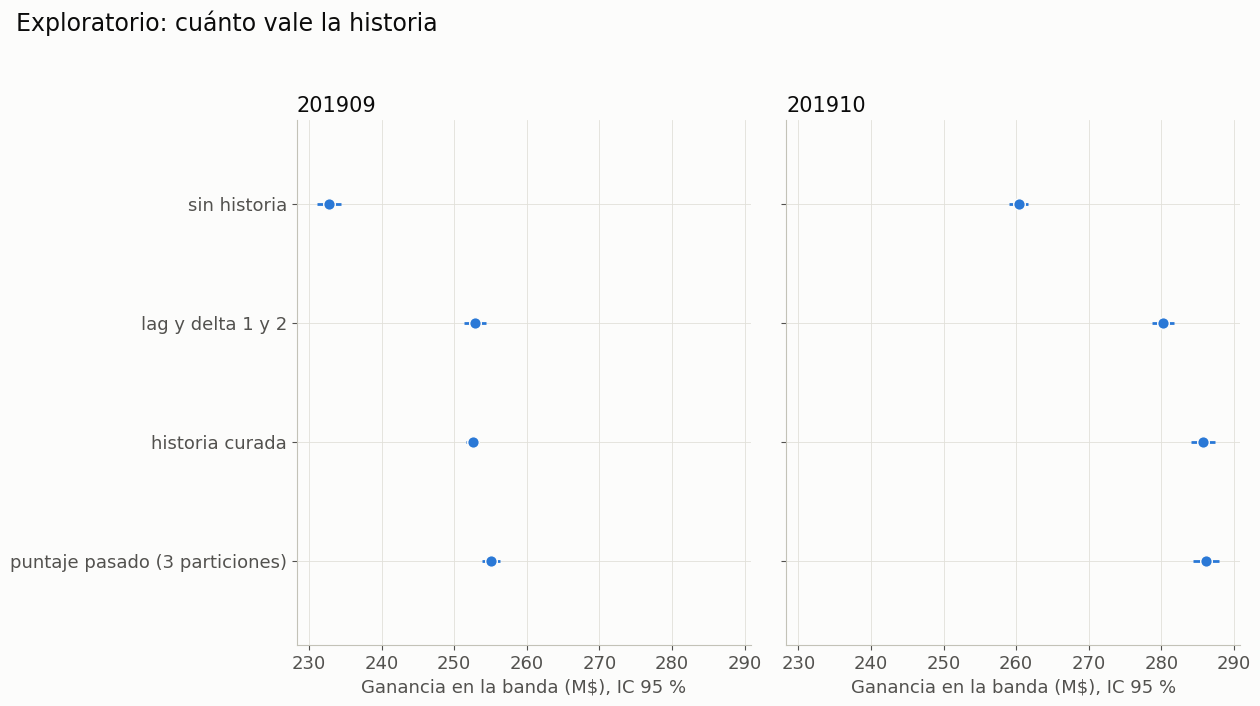

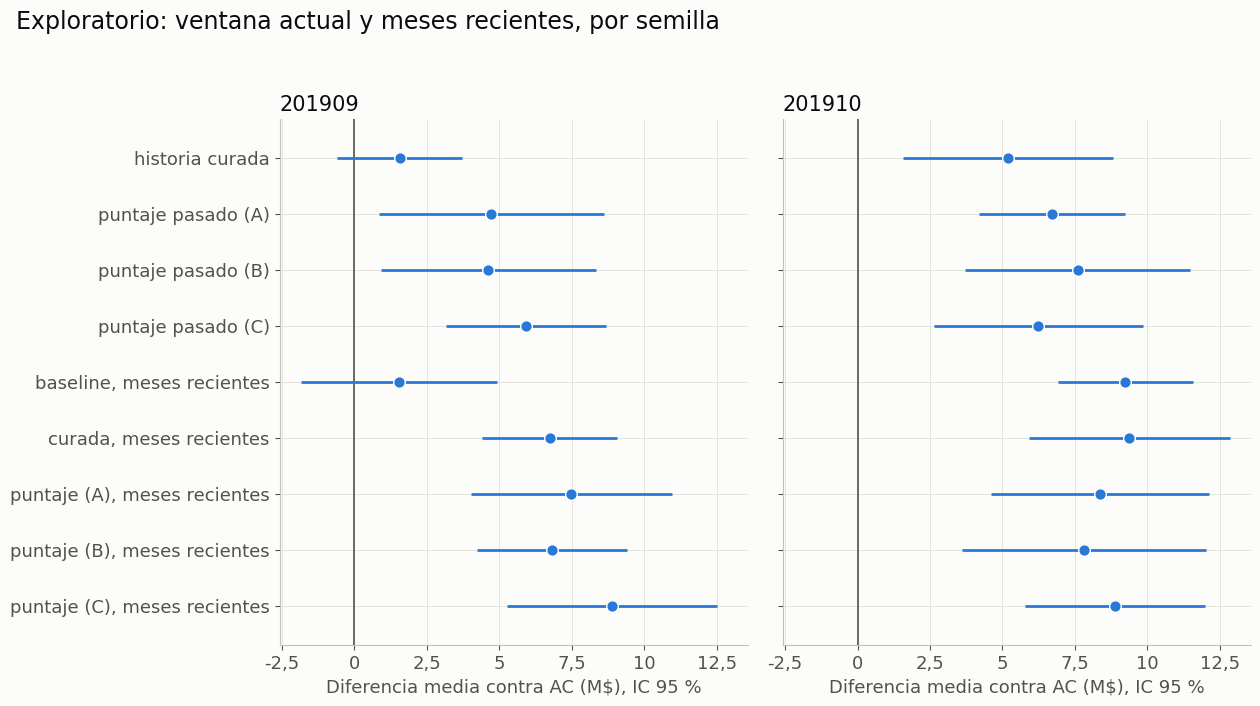

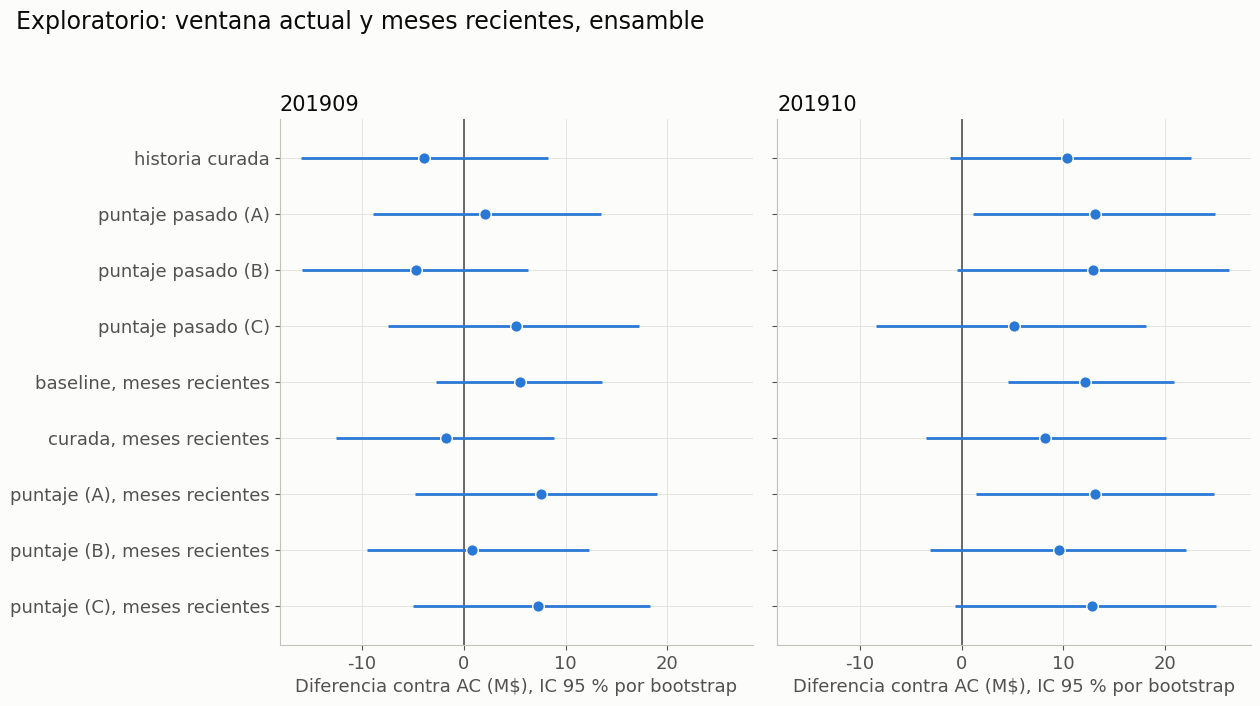

In [7]:
TINTA_2, GRILLA, AZUL = '#52514e', '#e1e0d9', '#2a78d6'
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7',
                     'axes.labelcolor': TINTA_2, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2, 'text.color': '#0b0b0b',
                     'axes.grid': True, 'grid.color': GRILLA, 'grid.linewidth': 0.6, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 13, 'axes.titlesize': 15})
TAMANO, DPI = (12.8, 7.2), 150


def coma(x, decimales=1):
    return f'{x:,.{decimales}f}'.replace(',', '_').replace('.', ',').replace('_', '.')



NOMBRES = {'ACH': 'historia curada', 'ACPH': 'puntaje pasado (A)', 'ACPH_B': 'puntaje pasado (B)', 'ACPH_C': 'puntaje pasado (C)',
           'AC_R': 'baseline, meses recientes', 'ACH_R': 'curada, meses recientes', 'ACPH_R': 'puntaje (A), meses recientes',
           'ACPH_R_B': 'puntaje (B), meses recientes', 'ACPH_R_C': 'puntaje (C), meses recientes'}
LISTA = CONTRASTES[CONTROL]


def por_semilla(grupo, m):
    return np.mean([B[(c, m)] for c in grupo], axis=0)


def figura_valor():
    grupos = {'sin historia': [SIN_LAGS], 'lag y delta 1 y 2': [CONTROL], 'historia curada': [BASE_CURADA], 'puntaje pasado (3 particiones)': TRES}
    fig, ejes = plt.subplots(1, 2, figsize=TAMANO, sharex=True)
    y = np.arange(len(grupos))[::-1]
    for ax, m in zip(ejes, MESES_TEST):
        medias, inf, sup = zip(*[ic(por_semilla(g, m)) for g in grupos.values()])
        ax.hlines(y, inf, sup, color=AZUL, lw=2)
        ax.scatter(medias, y, s=70, color=AZUL, zorder=3, edgecolor='#fcfcfb')
        ax.set_yticks(y, list(grupos) if ax is ejes[0] else [])
        ax.set_ylim(-0.7, len(grupos) - 0.3)
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: coma(v, 0)))
        ax.set_title(str(m), loc='left')
        ax.set_xlabel('Ganancia en la banda (M$), IC 95 %')
    fig.suptitle('Exploratorio: cuánto vale la historia', x=0.02, ha='left', fontsize=17)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    fig.savefig(FIGURAS / '12_1_valor_historia.png', dpi=DPI)
    plt.show()


def figura(medida, titulo, rotulo, archivo):
    fig, ejes = plt.subplots(1, 2, figsize=TAMANO, sharex=True)
    etiquetas = [NOMBRES[c] for c in LISTA]
    y = np.arange(len(etiquetas))[::-1]
    for ax, m in zip(ejes, MESES_TEST):
        t = comparacion[(comparacion['medida'] == medida) & (comparacion['foto_mes'] == m) & (comparacion['contra'] == CONTROL)].set_index('config').loc[LISTA]
        ax.axvline(0, color=TINTA_2, lw=1.2)
        ax.hlines(y, t['ic95_inf_M'], t['ic95_sup_M'], color=AZUL, lw=2)
        ax.scatter(t['d_M'], y, s=70, color=AZUL, zorder=3, edgecolor='#fcfcfb')
        ax.set_yticks(y, etiquetas if ax is ejes[0] else [])
        ax.set_ylim(-0.7, len(etiquetas) - 0.3)
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: coma(v, 0 if float(v).is_integer() else 1)))
        ax.set_title(str(m), loc='left')
        ax.set_xlabel(rotulo)
    fig.suptitle(titulo, x=0.02, ha='left', fontsize=17)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    fig.savefig(FIGURAS / archivo, dpi=DPI)
    plt.show()


figura_valor()
figura('semillas', 'Exploratorio: ventana actual y meses recientes, por semilla',
       'Diferencia media contra AC (M$), IC 95 %', '12_2_por_semilla.png')
figura('ensamble', 'Exploratorio: ventana actual y meses recientes, ensamble',
       'Diferencia contra AC (M$), IC 95 % por bootstrap', '12_3_ensamble.png')

## 8. Lecturas fijadas antes de correr

Las cuatro lecturas de la ficha, aplicadas tal como quedaron escritas. La cuarta reemplaza a la regla del `11`, y ese cambio se hizo después de ver sus resultados.

**Control:** las salidas anteriores no cambiaron.

In [8]:
assert huella_archivos() == HUELLA_INICIAL, 'Cambiaron las salidas anteriores'   # control 9
print(f'Control de salidas OK · {(time.time() - T_INICIO) / 60:.1f} min en total · memoria máxima {memoria_gb()} GB')
if segundos:
    print('Segundos por modelo:', {c: round(float(np.mean(v)), 1) for c, v in segundos.items()})
print()
print('EXPLORATORIO: no cambia el resultado de la regla pre-registrada.')
print()


def banda_grupo(grupo, m):
    return float(np.mean([B[(c, m)].mean() for c in grupo]))


FAMILIAS = {'AC': [CONTROL], 'ACH': [BASE_CURADA], 'ACPH': TRES, 'AC_R': ['AC_R'], 'ACH_R': ['ACH_R'], 'ACPH_R': TRES_R}
diferencia = lambda a, b: [banda_grupo(a, m) - banda_grupo(b, m) for m in MESES_TEST]
texto = lambda v: ' y '.join(f'{x:+.2f}' for x in v)

t = comparacion[(comparacion['config'] == CONTROL) & (comparacion['contra'] == SIN_LAGS)]
s_, e_ = t[t['medida'] == 'semillas'], t[t['medida'] == 'ensamble']
gana, excluye = bool((s_['d_banda_M'] > 0).all()), bool((e_['ic95_inf_M'] > 0).all())
print('1. ¿Cuánto vale la historia?')
print('  ', 'Se sostiene' if gana and excluye else 'La historia vale, pero no se puede medir cuánto' if gana else 'La reformulación cae')
print(f'   Primeros 2 meses (AC - ACS), banda: {texto(diferencia([CONTROL], [SIN_LAGS]))} M')
print(f'   Mirar más atrás (ACPH - AC), banda: {texto(diferencia(TRES, [CONTROL]))} M')
print()

pares = {'AC': ([CONTROL], ['AC_R']), 'ACH': ([BASE_CURADA], ['ACH_R']), 'ACPH': (TRES, TRES_R)}
suben = {}
print('2. ¿Rinden los meses recientes?')
for nombre_familia, (actual, reciente) in pares.items():
    d = diferencia(reciente, actual)
    suben[nombre_familia] = all(x > 0 for x in d)
    print(f'   {nombre_familia}: {texto(d)} M')
print('  ', 'Sí' if all(suben.values()) else 'Depende de las variables' if any(suben.values()) else 'No')
print()

print('3. ¿La historia sigue sumando con los meses recientes?')
for nombre_familia, grupo in (('ACH_R', ['ACH_R']), ('ACPH_R', TRES_R)):
    d = diferencia(grupo, ['AC_R'])
    print(f'   {nombre_familia} contra AC_R: {texto(d)} M · {"suma" if all(x > 0 for x in d) else "no suma"}')
print()

tabla = pd.DataFrame({f: {m: banda_grupo(g, m) for m in MESES_TEST} for f, g in FAMILIAS.items()}).T
tabla['media'] = tabla[MESES_TEST].mean(axis=1)
print('4. Estrategia que gana más dinero (banda por semilla, M; ACPH y ACPH_R con media de 3 particiones):')
print(tabla.sort_values('media', ascending=False).round(2).to_string())
print()
print('Gana:', tabla['media'].idxmax())

Control de salidas OK · 101.8 min en total · memoria máxima 6.1 GB
Segundos por modelo: {'ACS': 9.9, 'AC_R': 50.7, 'ACH_R': 60.5, 'ACPH_R': 60.8, 'ACPH_R_B': 60.7, 'ACPH_R_C': 60.9}

EXPLORATORIO: no cambia el resultado de la regla pre-registrada.

1. ¿Cuánto vale la historia?
   Se sostiene
   Primeros 2 meses (AC - ACS), banda: +20.14 y +19.93 M
   Mirar más atrás (ACPH - AC), banda: +2.15 y +5.90 M

2. ¿Rinden los meses recientes?
   AC: +1.04 y +6.44 M
   ACH: +3.00 y +2.09 M
   ACPH: +3.64 y +1.52 M
   Sí

3. ¿La historia sigue sumando con los meses recientes?
   ACH_R contra AC_R: +1.57 y +1.10 M · suma
   ACPH_R contra AC_R: +4.75 y +0.98 M · suma

4. Estrategia que gana más dinero (banda por semilla, M; ACPH y ACPH_R con media de 3 particiones):
        201909  201910   media
ACPH_R  258.71  287.71  273.21
ACH_R   255.54  287.82  271.68
ACPH    255.07  286.19  270.63
AC_R    253.96  286.73  270.35
ACH     252.54  285.73  269.13
AC      252.93  280.29  266.61

Gana: ACPH_R
